# Fitting with a PyTorch emulator in Gammapy

Many physical emission models are slow:
a single evaluation can take from milliseconds to seconds up to minutes for hadronic models, and a fit needs thousands of them.
A solution to this is to replace the model by an **emulator** (or *surrogate*): a neural network trained once to
reproduce the model output as a function of its parameters. Once trained, the network is fast, smooth and differentiable.

In this hands-on we show how such a network, trained with [PyTorch](https://pytorch.org/), can be used as a
**Gammapy spectral model** like any other. To be able to check the answer exactly, the "physical model" here is
the simplest one possible: a **power law**.

Yes, this is complete overkill for a power law. The point is the workflow, which is identical for an expensive model.

**What you get**
- `pl_emulator.pt`: the trained network. How it was trained is *not* part of this session.

**What we do**
1. Load H.E.S.S. data of the Crab Nebula
2. Load the emulator and check what it has learnt
3. Write a custom Gammapy `SpectralModel` that calls the network
4. Fit a standard `PowerLawSpectralModel`
5. Fit the emulator
6. Compare the two

See also the *NaimaSurrogate* notebook of the advanced hands-on, which does the same with a scikit-learn surrogate of a Naima model,
and the Gammapy documentation on [custom models](https://docs.gammapy.org/2.1/tutorials/details/models.html#implementing-a-custom-model).

> **Requirements**: Gammapy 2.1 and PyTorch (the CPU version is enough):
> `pip install torch --index-url https://download.pytorch.org/whl/cpu`

In [1]:
pip install torch --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.


## 0. Imports

In [2]:
import json
import time

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.table import Table

import torch

from gammapy.datasets import Datasets, SpectrumDatasetOnOff
from gammapy.estimators import FluxPointsEstimator
from gammapy.modeling import Fit, Parameter
from gammapy.modeling.models import (
    Models,
    PowerLawSpectralModel,
    SkyModel,
    SpectralModel,
    SPECTRAL_MODEL_REGISTRY,
)

print(f"torch {torch.__version__}")

torch 2.15.0+cpu


## 1. The data: H.E.S.S. observations of the Crab Nebula

We use the four Crab runs of the H.E.S.S which are shipped in `$GAMMAPY_DATA`.
This is exactly the output you obtain at the end of the *1D spectral analysis* hands-on.

In [3]:
runs = [23523, 23526, 23559, 23592]
path = "$GAMMAPY_DATA/joint-crab/spectra/hess"

datasets = Datasets(
    [SpectrumDatasetOnOff.read(f"{path}/pha_obs{run}.fits", format="ogip") for run in runs]
)
datasets.info_table()

name,counts,excess,sqrt_ts,background,npred,npred_background,npred_signal,exposure_min,exposure_max,livetime,ontime,counts_rate,background_rate,excess_rate,n_bins,n_fit_bins,stat_type,stat_sum,counts_off,acceptance,acceptance_off,alpha
,,,,,,,,cm2 s,cm2 s,s,s,1 / s,1 / s,1 / s,,,,,,,,
str5,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,str5,float64,int64,float64,float64,float64
23523,124,116.33333333333333,18.872041574506593,7.666666666666666,16.615384615384617,16.615384615384617,nan,2949059052.1246433,8376231456354.887,1581.736758410931,nan,0.0783948399382049,0.004846992791878259,0.07354784714632663,80,41,wstat,391.5527060344937,92,41.0,492.0,0.08333333333333333
23526,126,117.41666666666667,18.646945335906672,8.583333333333332,17.615384615384613,17.615384615384613,nan,10591478518.00296,7315139680580.923,1572.68672400713,nan,0.08011767256415701,0.005457751504039795,0.07465992106011722,80,43,wstat,387.043993755737,103,43.0,516.0,0.08333333333333333
23559,119,113.6,21.414517684785114,5.4,8.170731707317074,8.170731707317074,nan,5936739974.77126,5322302344014.188,1578.123517513275,nan,0.0754060114302802,0.003421785392634564,0.07198422603764563,80,43,wstat,500.007072425908,216,43.0,1720.0,0.025
23592,90,84.15,17.23755606553585,5.8500000000000005,7.902439024390246,7.902439024390246,nan,1811184844.7631397,5758535526100.256,1581.264640688896,nan,0.05691646906161797,0.0036995704890051685,0.0532168985726128,80,41,wstat,325.28264198381686,234,41.0,1640.0,0.025


we stack the four runs into a single dataset.

In [4]:
stacked = datasets.stack_reduce(name="crab-stacked")
print(stacked)

SpectrumDatasetOnOff
--------------------

  Name                            : crab-stacked 

  Total counts                    : 459 
  Total background counts         : 27.50
  Total excess counts             : 431.50

  Predicted counts                : 45.27
  Predicted background counts     : 45.27
  Predicted excess counts         : nan

  Exposure min                    : 2.13e+06 m2 s
  Exposure max                    : 2.63e+09 m2 s

  Number of total bins            : 80 
  Number of fit bins              : 43 

  Fit statistic type              : wstat
  Fit statistic value (-2 log(L)) : 1530.36

  Number of models                : 0 
  Number of parameters            : 0
  Number of free parameters       : 0

  Total counts_off                : 645 
  Acceptance                      : 168 
  Acceptance off                  : 4497 



## 2. The emulator

### 2.1 Loading the network

The file is a TorchScript file: it contains both the architecture and the trained weights, so we do **not**
need the Python class used for the training. Some extra information (validity range, reference energy) is stored
alongside the weights, in a small JSON file inside the archive.

We convert the network to **float64**. Minuit computes derivatives numerically, with tiny parameter steps:
in single precision, the model output is too "grainy" for that.

In [5]:
EMULATOR_FILE = "pl_emulator.pt"

def load_emulator(filename):
    """Load a TorchScript emulator and its metadata."""
    extra_files = {"meta.json": ""}
    network = torch.jit.load(filename, map_location="cpu", _extra_files=extra_files)
    network = network.double().eval()        # float64, inference mode
    meta = json.loads(extra_files["meta.json"])
    return network, meta

network, meta = load_emulator(EMULATOR_FILE)

print(network)
print(json.dumps(meta, indent=2))

RecursiveScriptModule(
  original_name=PowerLawEmulator
  (net): RecursiveScriptModule(
    original_name=Sequential
    (0): RecursiveScriptModule(original_name=Linear)
    (1): RecursiveScriptModule(original_name=SiLU)
    (2): RecursiveScriptModule(original_name=Linear)
    (3): RecursiveScriptModule(original_name=SiLU)
    (4): RecursiveScriptModule(original_name=Linear)
    (5): RecursiveScriptModule(original_name=SiLU)
    (6): RecursiveScriptModule(original_name=Linear)
  )
)
{
  "description": "PyTorch emulator of a power-law shape: (log10(E/TeV), index) -> log10(dN/dE / amplitude)",
  "energy_unit": "TeV",
  "reference_energy_TeV": 1.0,
  "log10_energy_range": [
    -1.5,
    2.3
  ],
  "index_range": [
    1.0,
    4.5
  ],
  "val_max_abs_dlog10": 0.004914628822796807
}


/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


The network is a small multilayer perceptron with 3 hidden layers of 32 neurons. It takes two inputs,
$\log_{10}(E/\mathrm{TeV})$ and the index $\Gamma$, and returns

$$y = \log_{10}\left(\frac{1}{\phi_0}\frac{dN}{dE}\right) \quad\left(= -\Gamma \log_{10}\frac{E}{1\,\mathrm{TeV}} \text{ for the true power law}\right)$$

Note that the amplitude $\phi_0$ is **not** an input of the network: the model is linear in it, so there is no point in learning it.
This is also what you would do for a real emulator: learn the *shape* and keep the normalisation analytic.



### 2.2 What has the network learnt?

The network works with `torch.Tensor` objects. We evaluate it on a grid of energies for a few indices and compare
with the exact power law.

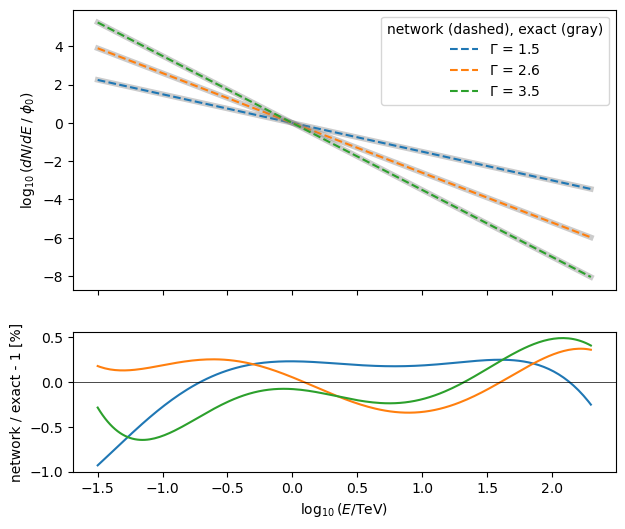

In [6]:
log10_energy = np.linspace(*meta["log10_energy_range"], 200)

fig, (ax, ax_res) = plt.subplots(2, 1, figsize=(7, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

for index in [1.5, 2.6, 3.5]:
    with torch.no_grad():
        y_net = network(torch.tensor(log10_energy), torch.tensor(index)).numpy()
    y_true = -index * log10_energy

    ax.plot(log10_energy, y_true, color="gray", lw=4, alpha=0.4)
    ax.plot(log10_energy, y_net, ls="--", label=f"$\\Gamma$ = {index}")
    ax_res.plot(log10_energy, 100 * (10 ** (y_net - y_true) - 1))

ax.set_ylabel(r"$\log_{10}(dN/dE \;/\; \phi_0)$")
ax.legend(title="network (dashed), exact (gray)")
ax_res.axhline(0, color="k", lw=0.5)
ax_res.set_xlabel(r"$\log_{10}(E/\mathrm{TeV})$")
ax_res.set_ylabel("network / exact - 1 [%]")
plt.show()

The emulator reproduces the power law to better than ~1% over its validity range. Outside this range, a neural network
has no reason to behave sensibly: we will have to make sure the fit never goes there.

## 3. A custom Gammapy spectral model calling the network

A Gammapy spectral model needs ([docs](https://docs.gammapy.org/2.1/tutorials/details/models.html#implementing-a-custom-model)):
- a `tag`: its name, used when it is written to / read from YAML,
- its parameters, declared as class attributes (`Parameter`),
- an `evaluate(energy, **parameters)` method returning $dN/dE$ as an astropy `Quantity`.

All the PyTorch-specific code sits in `evaluate`: convert `numpy` → `torch`, call the network, convert back.

Two details matter:
- Gammapy sometimes calls `evaluate` with arrays of energies **and** arrays of parameter values (e.g. to sample the
  parameters when it computes error bands). We broadcast the two before flattening them for the network.
- The index limits are set to the training range of the emulator, so Minuit cannot push the network into
  extrapolation.


In [7]:
class EmulatedPowerLawSpectralModel(SpectralModel):
    """Power law whose shape is computed by a PyTorch network.

    dN/dE = amplitude * 10 ** network(log10(E / TeV), index)

    Parameters
    ----------
    filename : str
        TorchScript file of the emulator.
    index : float
        Spectral index.
    amplitude : `~astropy.units.Quantity`
        Differential flux at 1 TeV.
    """

    tag = ["EmulatedPowerLawSpectralModel", "torch-pl"]
    index = Parameter("index", 2.0)
    amplitude = Parameter("amplitude", "1e-12 cm-2 s-1 TeV-1", interp="log")

    def __init__(self, filename=EMULATOR_FILE, **kwargs):
        self.filename = str(filename)
        self.network, self.meta = load_emulator(self.filename)
        super().__init__(**kwargs)
        # never let the fit leave the domain the network was trained on. Make sure to not broaden the allowed min and max later when loading the model
        self.index.min, self.index.max = self.meta["index_range"]

    def evaluate(self, energy, index, amplitude):
        log10_energy = np.log10(u.Quantity(energy, "TeV").value)
        # energy and index can both be arrays: bring them to the same shape
        log10_energy, index = np.broadcast_arrays(log10_energy, u.Quantity(index).to_value(""))

        with torch.no_grad():
            y = self.network(
                torch.as_tensor(log10_energy.ravel(), dtype=torch.float64),
                torch.as_tensor(index.ravel(), dtype=torch.float64),
            )

        shape = 10 ** y.numpy().reshape(log10_energy.shape)
        return amplitude * shape


# tell Gammapy about the new model type, needed by Models.read()
if EmulatedPowerLawSpectralModel not in SPECTRAL_MODEL_REGISTRY:
    SPECTRAL_MODEL_REGISTRY.append(EmulatedPowerLawSpectralModel)

It now behaves like any Gammapy spectral model: it can be evaluated, printed, plotted...

In [8]:
emu_test = EmulatedPowerLawSpectralModel(index=2.6, amplitude="4e-11 cm-2 s-1 TeV-1")
pl_test = PowerLawSpectralModel(index=2.6, amplitude="4e-11 cm-2 s-1 TeV-1", reference="1 TeV")

energy = [0.1, 1, 10, 100] * u.TeV
print(emu_test(energy))
print(pl_test(energy))
emu_test

[1.59542463e-08 4.00218221e-11 1.00141056e-13 2.53151886e-16] 1 / (TeV s cm2)
[1.59242868e-08 4.00000000e-11 1.00475457e-13 2.52382938e-16] 1 / (TeV s cm2)


/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


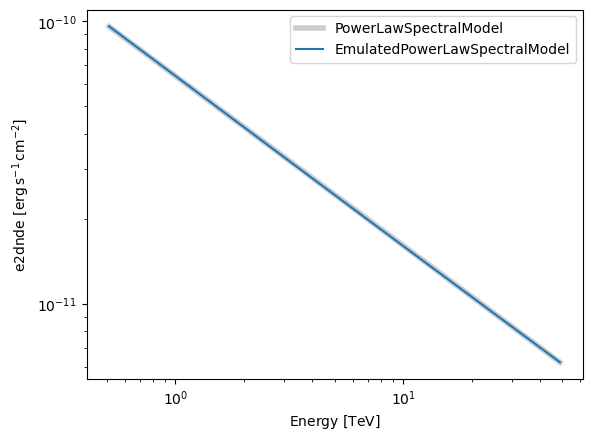

In [9]:
energy_bounds = [0.5, 50] * u.TeV
ax = pl_test.plot(energy_bounds, sed_type="e2dnde", lw=4, alpha=0.4, color="gray", label="PowerLawSpectralModel")
emu_test.plot(energy_bounds, ax=ax, sed_type="e2dnde", label="EmulatedPowerLawSpectralModel")
ax.legend()
plt.show()

## 4. Fit 1: the standard power law

First fit a standard powerlaw model to the data, print the results and safe the time it needs for the fit.
For the emulator a reference energy of 1 TeV is fixed, so make sure to use the same here

In [10]:
pl = PowerLawSpectralModel(index=2.5, amplitude="1e-11 cm-2 s-1 TeV-1", reference="1 TeV")
stacked.models = SkyModel(spectral_model=pl, name="crab-pl")

fit = Fit()
t0 = time.perf_counter()
result_pl = fit.run(stacked)
t_fit_pl = time.perf_counter() - t0

print(result_pl)
print(f"fit time: {t_fit_pl:.2f} s")

OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 64
	total stat : 36.41

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.

fit time: 0.11 s


In [11]:
stacked.models.to_parameters_table()

model,type,name,value,unit,error,min,max,frozen,link,prior
str7,str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
crab-pl,,index,2.6982e+00,,7.131e-02,nan,nan,False,,
crab-pl,,amplitude,4.5723e-11,TeV-1 s-1 cm-2,2.737e-12,nan,nan,False,,
crab-pl,,reference,1.0000e+00,TeV,0.000e+00,nan,nan,True,,


keep a copy of the dataset with this model, for the plots at the end.

In [12]:
stacked_pl = stacked.copy(name="crab-stacked-pl")
stacked_pl.models = stacked.models.copy()

## 5. Fit 2: the emulator

Now do the same but use the emulator as a model:

In [13]:
emu = EmulatedPowerLawSpectralModel(index=2.5, amplitude="1e-11 cm-2 s-1 TeV-1")
stacked.models = SkyModel(spectral_model=emu, name="crab-torch")

t0 = time.perf_counter()
result_emu = fit.run(stacked)
t_fit_emu = time.perf_counter() - t0

print(result_emu)
print(f"fit time: {t_fit_emu:.2f} s")

/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 71
	total stat : 36.45

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.

fit time: 0.22 s


In [14]:
stacked.models.to_parameters_table()

model,type,name,value,unit,error,min,max,frozen,link,prior
str10,str1,str9,float64,str14,float64,float64,float64,bool,str1,str1
crab-torch,,index,2.6973e+00,,7.153e-02,1.000e+00,4.500e+00,False,,
crab-torch,,amplitude,4.5764e-11,TeV-1 s-1 cm-2,2.754e-12,nan,nan,False,,


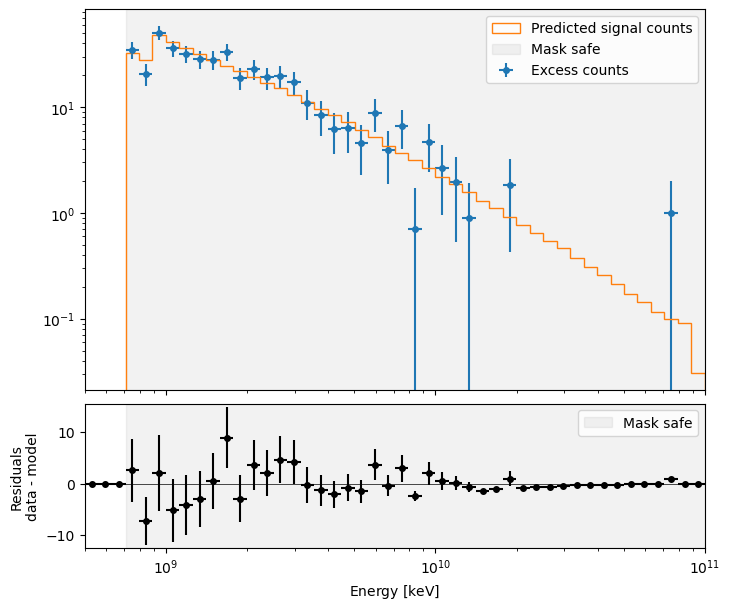

In [15]:
ax_spectrum, ax_residuals = stacked.plot_fit()
# the OGIP files store energies in keV: zoom on the fitted range (0.5-100 TeV)
for ax in [ax_spectrum, ax_residuals]:
    ax.set_xlim((0.5 * u.TeV).to_value("keV"), (100 * u.TeV).to_value("keV"))
plt.show()

## 6. Comparison

### 6.1 Best-fit parameters

Compare the resulting parameters

In [16]:
rows = []
for name in ["index", "amplitude"]:
    p_pl, p_emu = pl.parameters[name], emu.parameters[name]
    rows.append([name, p_pl.value, p_pl.error, p_emu.value, p_emu.error,
                 (p_emu.value - p_pl.value) / p_pl.error])

table = Table(rows=rows, names=["parameter", "PL value", "PL error", "emu value", "emu error", "diff / sigma"])
for col in table.colnames[1:]:
    table[col].format = ".4g"
table

parameter,PL value,PL error,emu value,emu error,diff / sigma
str9,float64,float64,float64,float64,float64
index,2.698,0.07131,2.697,0.07153,-0.01209
amplitude,4.572e-11,2.737e-12,4.576e-11,2.754e-12,0.01488


And compare the log likelihoods of the two results:

In [17]:
print(f"-2 log L  power law: {result_pl.total_stat:.3f}")
print(f"-2 log L  emulator : {result_emu.total_stat:.3f}")
print(f"difference         : {result_emu.total_stat - result_pl.total_stat:.3f}")

-2 log L  power law: 36.405
-2 log L  emulator : 36.448
difference         : 0.043


The two fits agree to a few hundredths of a standard deviation, and the fit statistics differ by much less than 1:
the emulator error is negligible compared to the statistical uncertainties of the data.

### 6.2 Spectral energy distribution

Plot the different models:



/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


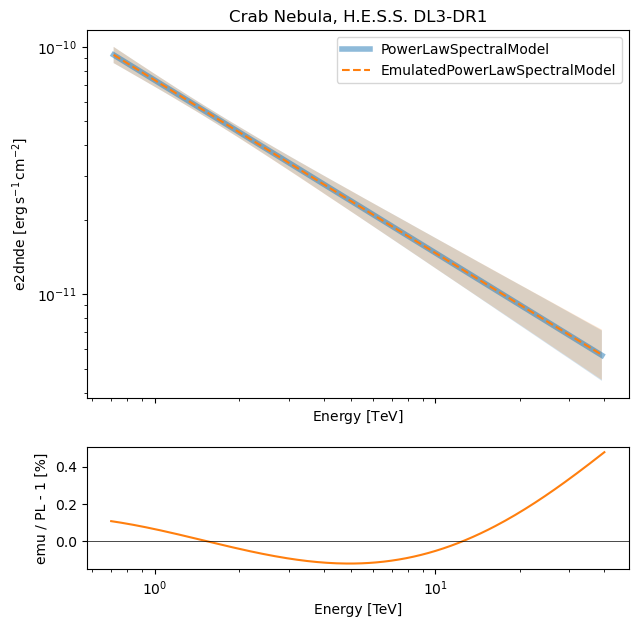

In [18]:
energy_bounds = [0.7, 40] * u.TeV
sed = dict(energy_bounds=energy_bounds, sed_type="e2dnde")

fig, (ax, ax_ratio) = plt.subplots(2, 1, figsize=(7, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

pl.plot(ax=ax, color="C0", lw=4, alpha=0.5, label="PowerLawSpectralModel", **sed)
pl.plot_error(ax=ax, facecolor="C0", alpha=0.2, **sed)
emu.plot(ax=ax, color="C1", ls="--", label="EmulatedPowerLawSpectralModel", **sed)
emu.plot_error(ax=ax, facecolor="C1", alpha=0.2, **sed)
ax.legend()
ax.set_title("Crab Nebula, H.E.S.S. DL3-DR1")

e = np.geomspace(*energy_bounds.value, 200) * u.TeV
ax_ratio.plot(e, 100 * (emu(e) / pl(e) - 1), color="C1")
ax_ratio.axhline(0, color="k", lw=0.5)
ax_ratio.set_xscale("log")
ax_ratio.set_xlabel("Energy [TeV]")
ax_ratio.set_ylabel("emu / PL - 1 [%]")
plt.show()

### 6.4 Speed
Compare the saved times needed for both fits:

For a power law, the emulator is **slower** than the analytic formula. Which for other more complex models might be the opposite and one of the main reasons to use emulators

In [19]:
def time_model(model, energy, n_rep=500):
    model(energy)                   # warm-up
    t0 = time.perf_counter()
    for _ in range(n_rep):
        model(energy)
    return (time.perf_counter() - t0) / n_rep

energy_true = stacked.exposure.geom.axes["energy_true"].center
t_pl = time_model(pl, energy_true)
t_emu = time_model(emu, energy_true)

print(f"PowerLawSpectralModel        : {1e6 * t_pl:8.1f} us / evaluation")
print(f"EmulatedPowerLawSpectralModel: {1e6 * t_emu:8.1f} us / evaluation")
print(f"fit time: {t_fit_pl:.2f} s (PL) vs {t_fit_emu:.2f} s (emulator)")

PowerLawSpectralModel        :    140.1 us / evaluation
EmulatedPowerLawSpectralModel:    338.5 us / evaluation
fit time: 0.11 s (PL) vs 0.22 s (emulator)
